# Данные МНСК в pandas

Запускайте ячейки сверху вниз в Jupyter на компьютере с папкой проекта. Можно сохранить этот ноутбук в любой другой папке. Требуется Python 3.10 или новее. Если пакеты ещё не установлены, выполните в отдельной ячейке:

```python
%pip install pandas numpy "openpyxl>=3.1,<3.2" matplotlib
```

Параметр `ROOT` указывает на локальную копию. Код читает книги с диска и создаёт объекты в памяти ядра Jupyter. Для загрузки достаточно выполнить первые две ячейки кода. Остальные показывают работу с конкретными листами МНСК.

In [1]:
from contextlib import ExitStack, closing
from pathlib import Path, PurePosixPath
from urllib.parse import unquote
from xml.etree import ElementTree as ET
from zipfile import ZipFile
import re

import numpy as np
import pandas as pd
from IPython.display import display
from openpyxl import load_workbook
from openpyxl.utils import get_column_letter

ROOT = Path(r"D:\GitHub_Desktop\china-public-sector-performance")
MAIN = "МНСК.xlsx"

## 1. Загрузить все листы и сопоставить внешние ссылки

У каждого листа есть ключ `(путь книги относительно ROOT, имя листа)`. В `values` лежат значения, в `formulas` — содержимое ячеек с выражениями Excel на местах формул. Координата `B5` читается как `.at[5, "B"]`. Номера строк, буквы столбцов, заголовки, промежутки и примечания сохраняются, в том числе на скрытых листах. При объединённых ячейках значение находится в их верхней левой ячейке.

Excel хранит в XLSX текст формулы и может сохранить результат последнего вычисления. pandas использует этот результат как снимок на момент сохранения. Изменения исходных значений в DataFrame сами по себе формулы Excel не пересчитывают. Если нужен свежий результат всей книги, можно открыть отдельную копию проекта в Excel, обновить внешние связи на файлы этой копии, пересчитать, сохранить и указать её путь в `ROOT`.

`catalog` перечисляет листы. `links` связывает номера вида `[1]` в формулах каждой книги с исходными файлами. Для ссылки со старым абсолютным адресом проверяется совпадение папки и имени внутри проекта. `issues` показывает адреса ошибок Excel и формул без сохранённого результата. Пустая строка, которую вернула формула, остаётся пустой строкой. Выражения используют имена функций в записи XLSX, например `IFERROR`, даже если Excel отображает их по-русски.

In [2]:
def local_source(book, target, files):
    """Сопоставляем внешний адрес только с уже найденными внутри проекта книгами."""
    path = unquote(target).replace("\\", "/")
    relative = (ROOT / book).parent / path
    if not path.startswith("file:") and relative.resolve() in files:
        return files[relative.resolve()], "по адресу ссылки"
    parts = [x.casefold() for x in PurePosixPath(path).parts]
    # Для старого абсолютного пути требуем совпадения как минимум папки и имени.
    for size in range(len(parts), 1, -1):
        matches = [key for key in files.values()
                   if [x.casefold() for x in PurePosixPath(key).parts][-size:] == parts[-size:]]
        if len(matches) == 1:
            return matches[0], "по окончанию пути"
        if matches:
            return None, "неоднозначная ссылка"
    return None, "источник не найден"


def empty_strings(archive, sheet):
    # У Excel строковый результат "" записан как t="str" с пустым тегом <v>.
    # При data_only=True openpyxl возвращает для него None, как и при отсутствии кэша.
    with archive.open(sheet._worksheet_path) as stream:
        root = ET.parse(stream).getroot()
    result = set()
    for cell in root.iterfind(".//{*}c[@t='str']"):
        value = cell.find("{*}v")
        if value is not None and value.text is None:
            result.add(cell.attrib["r"])
    return result


def excel_frame(rows):
    df = pd.DataFrame(rows, dtype=object)
    df.index = pd.RangeIndex(1, len(df) + 1, name="строка Excel")
    df.columns = [get_column_letter(i) for i in range(1, df.shape[1] + 1)]
    return df


def read_project():
    if not ROOT.is_dir():
        raise FileNotFoundError(f"Проверьте путь ROOT: {ROOT}")
    books = sorted(p for p in ROOT.rglob("*") if p.is_file()
                   and p.suffix.lower() == ".xlsx" and not p.name.startswith("~$"))
    files = {p.resolve(): p.relative_to(ROOT).as_posix() for p in books}
    if MAIN not in files.values():
        raise FileNotFoundError(f"В корне проекта не найдена книга {MAIN}.")

    values, formulas = {}, {}
    sheets, links, issues = [], [], []
    for path in books:
        book = files[path.resolve()]
        try:
            with ExitStack() as stack:
                wb = stack.enter_context(closing(load_workbook(path, read_only=True)))
                cache = stack.enter_context(closing(load_workbook(
                    path, read_only=True, data_only=True, keep_links=False)))
                archive = stack.enter_context(ZipFile(path))
                for number, link in enumerate(wb._external_links, start=1):
                    target = link.file_link.Target
                    source, status = local_source(book, target, files)
                    links.append((book, number, target, source, status))

                for sheet in wb.worksheets:
                    key = (book, sheet.title)
                    saved = cache[sheet.title]
                    blanks = empty_strings(archive, sheet)
                    # Читаем фактические строки даже у файлов с неверным XML-размером листа.
                    sheet.reset_dimensions()
                    saved.reset_dimensions()
                    vrows, frows = [], []
                    formula_count = blank_count = 0
                    for left, right in zip(sheet.rows, saved.rows, strict=True):
                        vr, fr = [], []
                        for cell, cached in zip(left, right, strict=True):
                            value = cached.value
                            if value is None and getattr(cell, "coordinate", None) in blanks:
                                value = ""
                            expression = cell.value
                            if cell.data_type == "f":
                                formula_count += 1
                                # openpyxl разворачивает общие формулы в формулу каждой ячейки.
                                # Для особых формул массива/таблицы сохраняем также их атрибуты.
                                if not isinstance(expression, str):
                                    expression = dict(vars(expression), type=type(expression).__name__)
                                if value is None:
                                    issues.append((*key, cell.coordinate, "нет сохранённого результата"))
                                elif value == "":
                                    blank_count += 1
                            if cached.data_type == "e":
                                issues.append((*key, cell.coordinate, value))
                            vr.append(value)
                            fr.append(expression)
                        vrows.append(vr)
                        frows.append(fr)
                    values[key], formulas[key] = excel_frame(vrows), excel_frame(frows)
                    sheets.append((*key, *values[key].shape, formula_count, blank_count))
        except Exception as exc:
            raise RuntimeError(f"Не удалось полностью прочитать {book}: {exc}") from exc

    catalog = pd.DataFrame(sheets, columns=["книга", "лист", "строк", "столбцов", "формул", "формул с результатом «»"])
    links = pd.DataFrame(links, columns=["книга", "номер", "адрес Excel", "источник", "статус"])
    issues = pd.DataFrame(issues, columns=["книга", "лист", "ячейка", "проблема"])
    return values, formulas, catalog, links, issues


values, formulas, catalog, links, issues = read_project()
print(f"Книг: {catalog['книга'].nunique()}, листов: {len(catalog)}, формул: {catalog['формул'].sum():,}")
display(catalog.head(), links.groupby(["книга", "статус"]).size().rename("ссылок").to_frame())
print("Ячеек с ошибками Excel или без сохранённого результата формулы:", len(issues))
display(issues.head(10))

Книг: 75, листов: 298, формул: 204,698


,книга,лист,строк,столбцов,формул,формул с результатом «»
0,01_lighting/1.xlsx,Sheet1,36,26,0,0
1,01_lighting/areas.xlsx,Province Areas,35,5,0,0
2,01_lighting/areas.xlsx,Area by Year,39,26,0,0
3,01_lighting/population.xlsx,Sheet1,36,26,0,0
4,02_electricity/2.xlsx,Sheet1,36,26,0,0


ссылок
книга     статус                   
I.xlsx    по адресу ссылки        1
W.xlsx    по адресу ссылки        1
МНСК.xlsx по адресу ссылки       70
          по окончанию пути       1

Ячеек с ошибками Excel или без сохранённого результата формулы: 0


,книга,лист,ячейка,проблема


## 2. Проследить путь от МНСК к исходной ячейке

Пекин, 2024 год, показатель № 1 «Освещенность улиц». В проверенной версии проекта числитель берётся из `01_lighting/1.xlsx`, площадь в км² и население — из двух других книг той же папки. Число жителей в исходнике дано в десятках тысяч.

In [3]:
indicator_sheet = "1. Освещенность улиц"
key = (MAIN, indicator_sheet)
print("МНСК, B5:", formulas[key].at[5, "B"])
print("Сохранённый результат:", values[key].at[5, "B"])
display(links.loc[(links["книга"] == MAIN) & links["номер"].isin([1, 2, 3])])
lights_key = ("01_lighting/1.xlsx", "Sheet1")
display(values[lights_key].iloc[:8, :7])

МНСК, B5: =IFERROR([1]Sheet1!B5/SQRT('[2]Area by Year'!B5*[3]Sheet1!B5*10000),"")
Сохранённый результат: 1.0664470539655477


,книга,номер,адрес Excel,источник,статус
2,МНСК.xlsx,1,01_lighting/1.xlsx,01_lighting/1.xlsx,по адресу ссылки
3,МНСК.xlsx,2,01_lighting/areas.xlsx,01_lighting/areas.xlsx,по адресу ссылки
4,МНСК.xlsx,3,01_lighting/population.xlsx,01_lighting/population.xlsx,по адресу ссылки


,A,B,C,D,E,F,G
строка Excel,,,,,,,
1,Database：Annual By Province,None,None,None,None,None,None
2,Indicators：Number of Street Lights (unit),None,None,None,None,None,None
3,Time：2000-2024,None,None,None,None,None,None
4,Region,2024,2023,2022,2021,2020,2019
5,Beijing,638313,319379,317412,312800,315285,309366
6,Tianjin,445667,439773,434559,419100,396388,377468
7,Hebei,1314832,1185156,1124609,1103700,1068008,1048477
8,Shanxi,622337,594699,556803,536400,512740,529855


In [4]:
lights = values[lights_key].at[5, "B"]
area = values[("01_lighting/areas.xlsx", "Area by Year")].at[5, "B"]
population = values[("01_lighting/population.xlsx", "Sheet1")].at[5, "B"]  # в 10 тыс. чел.
result = lights / np.sqrt(area * population * 10_000)
saved_value = values[key].at[5, "B"]
print("По исходным файлам:", result, "| В МНСК:", saved_value)
print("Совпадает:", isinstance(saved_value, (int, float)) and np.isclose(result, saved_value))

По исходным файлам: 1.0664470539655477 | В МНСК: 1.0664470539655477
Совпадает: True


## 3. Собрать таблицу для анализа

Одна строка `panel` соответствует паре «провинция, год». Столбцы содержат подготовленные показатели пронумерованных листов и сводный индекс из `I_Сводный`. Полные названия, единицы измерения и веса берутся из листа «Список показателей». Для нормированных показателей, агрегатов и пространственных матриц доступны соответствующие листы в `values`.

Названия провинций приводятся к русским по справочнику книги. Год берётся из заголовка каждого столбца. Строки источников и медиан исключаются из панели. В числовой панели пустые и нечисловые значения представлены как `NaN`. На исходном листе в `values` можно посмотреть, что именно было записано.

In [5]:
def with_header(df):
    table = df.iloc[1:].copy()
    table.columns = df.iloc[0].tolist()
    return table


dictionary = with_header(values[MAIN, "Список показателей"])
numbers = pd.to_numeric(dictionary["№"], errors="coerce")
metadata = dictionary.loc[numbers.notna()].copy()
metadata["№"] = numbers.dropna().astype(int)
metadata = metadata.set_index("№")
if not metadata.index.is_unique:
    raise ValueError("В справочнике повторяются номера показателей.")

names = with_header(values[MAIN, "Adjacency_names"])[["Province", "Русский"]].dropna()
to_ru = dict(zip(names["Province"], names["Русский"]))
to_ru.update({name: name for name in names["Русский"]})
to_ru["Xizang"] = to_ru["Tibet"]


def annual_series(sheet_name):
    df = values[MAIN, sheet_name]
    headers = df.index[df["A"].eq("Region")]
    if len(headers) != 1:
        raise ValueError(f"Проверьте заголовок Region на листе {sheet_name}")
    header = headers[0]
    years = {c: int(v) for c, v in df.loc[header].items()
             if re.fullmatch(r"(19|20)\d{2}", str(v))}
    if not years or len(set(years.values())) != len(years):
        raise ValueError(f"Проверьте годы на листе {sheet_name}")
    # В проверенной книге после Region идёт непрерывный блок из 31 провинции.
    block = df.loc[header + 1:header + len(names)].copy()
    regions = block["A"].map(to_ru)
    if set(regions) != set(names["Русский"]) or regions.duplicated().any():
        raise ValueError(f"Проверьте список и написание провинций на листе {sheet_name}")
    wide = block[list(years)].rename(columns=years)
    wide.index = regions.rename("провинция")
    long = wide.reset_index().melt(id_vars="провинция", var_name="год", value_name="значение")
    long["год"] = long["год"].astype(int)
    # Аналитическая копия. В values сохраняются исходные тексты, пустые строки и ошибки Excel.
    long["значение"] = pd.to_numeric(long["значение"], errors="coerce")
    annual = long.set_index(["провинция", "год"])["значение"]
    if not annual.index.is_unique:
        raise ValueError(f"Повторяется пара провинция и год на листе {sheet_name}")
    return annual


series = {}
for book, sheet_name in values:
    match = re.match(r"^(\d+)\.", sheet_name)
    if book == MAIN and match:
        number = int(match[1])
        if number in series:
            raise ValueError(f"Два листа показателя №{number}")
        series[number] = annual_series(sheet_name)
if set(series) != set(metadata.index):
    raise ValueError("Номера листов показателей расходятся со справочником МНСК.")
panel = pd.DataFrame(series).sort_index()
panel = panel.rename(columns=metadata["Название"].to_dict())
if panel.columns.has_duplicates:
    raise ValueError("В справочнике есть одноимённые показатели.")
panel = pd.concat([panel, annual_series("I_Сводный").rename("Сводный индекс")], axis=1).sort_index()
display(metadata[["Название", "Блок", "Единица измерения", "Балл"]].head())
print(f"Панель: {len(panel)} наблюдений, {len(metadata)} показателей и сводный индекс.")
display(panel.head())

,Название,Блок,Единица измерения,Балл
№,,,,
1,Освещенность улиц,Безопасность,"количество уличных фонарей, по коэффициенту Эн...",5
2,Генерация электроэнергии,Безопасность,КВт на 1 юань ВРП,4
3,Продовольственная безопасность,Безопасность,объем сельскохозяйственной продукции на душу н...,3
4,Протяженность оптических кабельных линий,Безопасность,"км, по коэффициенту Энгеля",4
5,Пострадавшие в ДТП,Безопасность,доля погибших и пострадавших в общей численнос...,2


Панель: 775 наблюдений, 55 показателей и сводный индекс.


Освещенность улиц  Генерация электроэнергии  \
провинция год                                                 
Аньхой    2000                NaN                  0.112399   
          2001                NaN                  0.112360   
          2002                NaN                  0.119944   
          2003                NaN                  0.127349   
          2004           0.089688                  0.116506   

                Продовольственная безопасность  \
провинция год                                    
Аньхой    2000                     2002.232070   
          2001                     2052.969974   
          2002                     2124.934896   
          2003                     2118.059387   
          2004                     2640.366089   

                Протяженность оптических кабельных линий  Пострадавшие в ДТП  \
провинция год                                                                  
Аньхой    2000                                       NaN                 NaN   
          2001                                       NaN            0.040338   
          2002                                       NaN            0.042072   
          2003                                       NaN            0.036877   
          2004                                       NaN            0.036407   

                Количество медицинских учреждений  \
провинция год                                       
Аньхой    2000                           0.002301   
          2001                           0.002408   
          2002                           0.003016   
          2003                           0.005352   
          2004                           0.003045   

                Количество медицинского персонала  Мощность коечного фонда  \
провинция год                                                                
Аньхой    2000                           0.064611                 0.042513   
          2001                           0.064905                 0.042836   
          2002                           0.062804                 0.040423   
          2003                           0.063424                 0.040565   
          2004                           0.064755                 0.041303   

                Количество общественных туалетов  \
провинция год                                      
Аньхой    2000                               NaN   
          2001                               NaN   
          2002                               NaN   
          2003                               NaN   
          2004                          0.001227   

                Выпускники высших учебных заведений  ...  \
провинция год                                        ...   
Аньхой    2000                             0.048909  ...   
          2001                             0.056136  ...   
          2002                             0.072103  ...   
          2003                             0.106604  ...   
          2004                             0.141940  ...   

                Вариация темпов прироста реального ВРП  \
провинция год                                            
Аньхой    2000                                     NaN   
          2001                                     NaN   
          2002                                     NaN   
          2003                                     NaN   
          2004                                     NaN   

                Производительность труда(продукт / занятых)  \
провинция год                                                 
Аньхой    2000                                          NaN   
          2001                                          NaN   
          2002                                          NaN   
          2003                                          NaN   
          2004                                          NaN   

                Обеспеченность почтовыми отделениями  \
провинция год                                       

## 4. Построить график

Каждая точка — годовое значение сводного индекса для одной провинции. Пропуски дают разрывы линии.

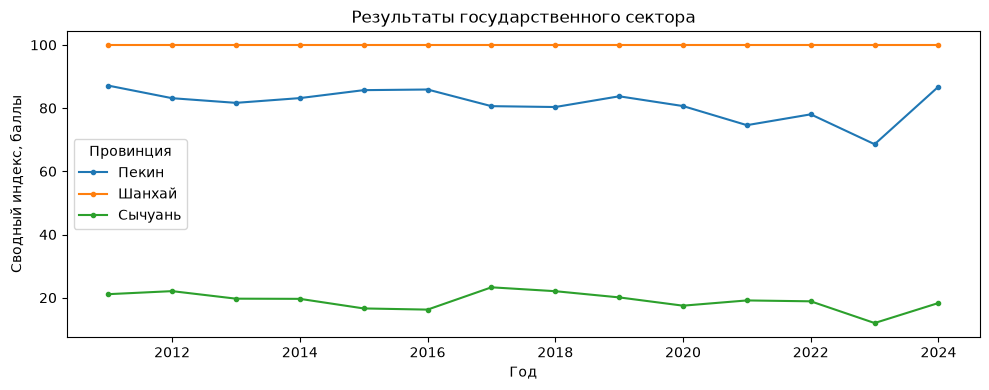

In [6]:
import matplotlib.pyplot as plt

psp = panel["Сводный индекс"].unstack("провинция")
ax = psp[["Пекин", "Шанхай", "Сычуань"]].plot(marker=".", figsize=(10, 4))
ax.set(xlabel="Год", ylabel="Сводный индекс, баллы", title="Результаты государственного сектора")
ax.legend(title="Провинция")
plt.tight_layout()
plt.show()

Чтобы получить данные одной провинции, выполните `panel.loc["Пекин"]`. Для среза по всем провинциям за один год используйте `panel.xs(2019, level="год")`. Результаты пространственного анализа по годам доступны как `values[MAIN, "Итог_Moran_Соседство"]`.

Структура и результаты проверены на [публичной версии проекта](https://github.com/Settara/china-public-sector-performance/tree/99c67e6db75be59972220a7900d8935ca2e2a08e). Локальный запуск использует файлы из `ROOT`.

## 5. Таблицы и карта в Gradio
Выполните ячейки загрузки и сборки панели выше. Для карты поместите папку `maps` с границами провинций и локальной подложкой Plotly в проект с МНСК. Источник контуров — [Natural Earth, 1:10m, Admin 1](https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-1-states-provinces/). Контуры Тайваня, Гонконга и Макао служат географическими ориентирами.

In [ ]:
%pip install "gradio>=5.49,<6" "plotly>=5.24,<6"

In [ ]:
import re
from html import escape
from numbers import Integral, Real

import gradio as gr
import pandas as pd


# Список таблиц из уже загруженных книг
INDICATOR = "Показатель"
RAW = "Ненормированный"
NORMAL = "Нормированный"
ALL = "Все таблицы проекта"

groups = {
    "Индексы и агрегаты": [],
    "Таблицы Морана": [],
    "Исходные книги": [],
    "Другие листы МНСК": [],
    ALL: [],
}

sheet_keys = sorted(values)
indicator_sheets = {}

for sheet_id, (book, sheet) in enumerate(sheet_keys):
    choice = (f"{book} › {sheet}", sheet_id)
    groups[ALL].append(choice)

    raw_match = re.match(r"^(\d+)\.", sheet)
    norm_match = re.match(r"^N_(\d+)_", sheet)

    if book == MAIN and (raw_match or norm_match):
        number = int((raw_match or norm_match).group(1))
        version = RAW if raw_match else NORMAL
        versions = indicator_sheets.setdefault(number, {})

        if version in versions:
            raise ValueError(f"Для показателя №{number} найдены два листа «{version}».")

        versions[version] = (book, sheet)

    elif book != MAIN:
        groups["Исходные книги"].append(choice)
    elif "moran" in sheet.casefold():
        groups["Таблицы Морана"].append(choice)
    elif sheet.startswith(("I_Блок", "I_Сводный", "P_Блок", "P_Сводный")):
        groups["Индексы и агрегаты"].append(choice)
    else:
        groups["Другие листы МНСК"].append(choice)


def cell_text(value):
    """Форматирование только для экрана."""
    if pd.isna(value):
        return ""

    if isinstance(value, bool):
        return str(value)

    if isinstance(value, Integral):
        return str(value)

    if isinstance(value, Real):
        # Например, 99.3554657068968 → 99,36
        return f"{value:.2f}".replace(".", ",")

    return escape(str(value))


def sheet_html(key):
    book, sheet = key
    df = values[key]
    rows = []
    annual = False

    for row in df.itertuples(index=False, name=None):
        # На годовых листах МНСК заголовок начинается с Region,
        # а следующие столбцы содержат годы.
        year_header = (
            len(row) >= 2
            and str(row[0]).strip().casefold() == "region"
            and re.fullmatch(r"(?:19|20)\d{2}(?:\.0)?", str(row[1]).strip())
            is not None
        )

        if year_header:
            annual = True
            cells = []
            for value in row:
                text = str(value).strip()
                if re.fullmatch(r"(?:19|20)\d{2}(?:\.0)?", text):
                    text = text[:4]  # 2024 остаётся годом без ",00"
                else:
                    text = cell_text(value)
                cells.append(f"<th>{text}</th>")
        else:
            cells = [f"<td>{cell_text(value)}</td>" for value in row]

        rows.append("<tr>" + "".join(cells) + "</tr>")

    # Фиксированная раскладка нужна для годовых таблиц.
    # У справочников и таблиц Морана ширина зависит от их содержимого.
    if annual:
        other_columns = df.shape[1] - 1
        table_style = f'class="annual" style="--other-cols:{other_columns}"'
        columns = (
            '<colgroup><col class="province-col">'
            f'<col span="{other_columns}"></colgroup>'
        )
    else:
        table_style = 'class="regular"'
        columns = ""

    title = escape(f"{book} › {sheet}")
    return (
        f'<p class="sheet-title">{title}</p>'
        '<div class="sheet-scroll" tabindex="0">'
        f'<table {table_style} aria-label="{title}">'
        f'{columns}<tbody>{"".join(rows)}</tbody>'
        '</table></div>'
    )


def select_table(category, number_text, version, selected, event: gr.EventData):
    is_indicator = category == INDICATOR
    text = (number_text or "").strip()
    number = int(text) if re.fullmatch(r"[0-9]{1,6}", text) else None

    versions = indicator_sheets.get(number, {})
    options = [name for name in (RAW, NORMAL) if name in versions] or [RAW, NORMAL]
    if version not in options:
        version = options[0]

    choices = groups.get(category, [])
    if event.target is category_box or selected not in {idx for _, idx in choices}:
        selected = None

    if is_indicator and versions:
        html = sheet_html(versions[version])
    elif is_indicator and text:
        html = "Такого номера нет среди загруженных показателей."
    elif is_indicator:
        html = "Введите номер показателя."
    elif selected is None:
        html = "Выберите книгу и лист."
    else:
        html = sheet_html(sheet_keys[selected])

    return (
        gr.update(visible=is_indicator),
        gr.update(
            visible=is_indicator,
            interactive=bool(versions),
            choices=options,
            value=version,
        ),
        gr.update(visible=not is_indicator, choices=choices, value=selected),
        html,
    )


css = """
.gradio-container {
    width: 100% !important;
    max-width: none !important;
}

#sheet-output {
    min-width: 0;
}

#sheet-output .sheet-title {
    margin: 0 0 6px;
    font-weight: 600;
}

#sheet-output .sheet-scroll {
    width: 100%;
    max-width: 100%;
    height: auto;
    max-height: none;
    overflow-x: auto;
    overflow-y: hidden;
    container-type: inline-size;
    border: 1px solid #bcc7d0;
}

#sheet-output table {
    margin: 0;
    border-collapse: separate;
    border-spacing: 0;
    color: var(--body-text-color);
    font-size: 12px;
    line-height: 1.2;
}

#sheet-output .annual {
    --province-width: clamp(110px, 13cqw, 175px);
    --year-width: clamp(64px, calc((100cqw - var(--province-width) - 2px) / 14), 98px);
    table-layout: fixed;
    width: calc(var(--province-width) + var(--other-cols) * var(--year-width));
    max-width: none;
}

#sheet-output .annual .province-col {
    width: var(--province-width);
}

#sheet-output .regular {
    width: max-content;
    min-width: 100%;
    max-width: none;
}

#sheet-output td,
#sheet-output th {
    box-sizing: border-box;
    border: solid #cdd5dc;
    border-width: 0 1px 1px 0;
    padding: 3px 5px;
    text-align: right;
    vertical-align: middle;
    font-variant-numeric: tabular-nums;
}

#sheet-output .annual td,
#sheet-output .annual th {
    white-space: normal;
    overflow-wrap: anywhere;
}

#sheet-output .regular td,
#sheet-output .regular th {
    white-space: pre-wrap;
    max-width: 36rem;
}

/* При прокрутке к ранним годам названия провинций остаются слева. */
#sheet-output tr > :first-child {
    position: sticky;
    left: 0;
    z-index: 1;
    text-align: left;
    background: var(--background-fill-primary, white);
}

#sheet-output th,
#sheet-output tr > th:first-child {
    background: var(--background-fill-secondary, #edf2f5);
    font-weight: 600;
}
"""


import json
from functools import lru_cache
import plotly.graph_objects as go

geo_file = ROOT / "maps" / "china_provinces.geojson"
with geo_file.open(encoding="utf-8") as stream:
    boundaries = json.load(stream)

# Локальная подложка Plotly позволяет открывать географический график без CDN.
with geo_file.with_name("world_110m.json").open(encoding="utf-8") as stream:
    world_json = json.dumps(json.load(stream), separators=(",", ":")).replace("<", r"\u003c")
map_head = ("<script>window.PlotlyGeoAssets = window.PlotlyGeoAssets || {topojson:{}};"
            "window.PlotlyGeoAssets.topojson.world_110m = " + world_json + ";</script>")

province_ids = [f["id"] for f in boundaries["features"] if f["properties"]["sample"]]
if len(province_ids) != 31 or set(province_ids) != set(names["Province"]):
    raise ValueError("Названия территорий GeoJSON расходятся со справочником Adjacency_names.")
ru_to_id = {to_ru[pid]: pid for pid in province_ids}

adj = values[MAIN, "Adjacency"]
header = adj.index[adj["A"].eq("Province")].item()
adj = adj.loc[header + 1:].set_axis(adj.loc[header], axis=1).set_index("Province")
adj = adj.loc[province_ids, province_ids]

RANK = "Место в выбранном году"
FIXED = "Значение индекса (1–100)"
overview = "I_Сводный"
map_options = [("Сводный индекс", overview)]
for n, block in enumerate(metadata["Блок"].drop_duplicates(), start=1):
    sheet = f"I_Блок{n}"
    if (MAIN, sheet) in values:
        map_options.append((f"Индекс блока {n} · {block}", sheet))
for number in sorted(indicator_sheets):
    map_options.append((f"{number}. {metadata.at[number, 'Название']}", str(number)))

@lru_cache(maxsize=160)
def province_years(sheet):
    return annual_series(sheet).unstack("год").sort_index(axis=1)

# Позиции заданы для шкалы от худшего результата (0) к лучшему (1).
palette = [(0, "#df2029"), (0.24, "#f27524"), (0.50, "#ffbd38"),
           (0.72, "#f6e852"), (0.78, "#b6d94d"), (1, "#08753b")]

def map_view(selection, version, year, mode, focus):
    number = int(selection) if selection.isdecimal() else None
    if number is None:
        sheet = selection
        options = [RANK, FIXED]
    else:
        sheet = indicator_sheets[number][version][1]
        options = [RANK]
    if mode not in options:
        mode = RANK

    matrix = province_years(sheet)
    years = list(map(int, matrix.columns))
    if year not in years:
        year = max(years)
    data = matrix[year].rename(index=ru_to_id).reindex(province_ids)
    data = data.replace([np.inf, -np.inf], np.nan)
    lower_is_better = False
    if number is not None and version == RAW:
        # Направление именно этого показателя берём из формулы нормирования МНСК.
        formula = formulas[indicator_sheets[number][NORMAL]].at[5, "B"]
        sign = re.search(r"100\s*([+-])", str(formula))
        if not sign:
            raise ValueError(f"Проверьте направление нормирования показателя №{number}.")
        lower_is_better = sign[1] == "-"
    ranks = data.rank(ascending=lower_is_better, method="min")
    count = int(data.count())
    if mode == FIXED:
        scores = (data - 1) / 99
    elif count and ranks.max() > 1:
        scores = 1 - (ranks - 1) / (ranks.max() - 1)
    else:
        scores = data.where(data.isna(), 1.0)

    figure = go.Figure()
    # Пропуски и территории вне выборки также рисуем, чтобы сохранялся контур карты.
    for group in ("значение", "нет данных", "вне выборки"):
        features, z, tips = [], [], []
        for feature in boundaries["features"]:
            pid = feature["id"]
            actual = ("вне выборки" if pid not in data.index else
                      "нет данных" if pd.isna(data[pid]) else "значение")
            if actual != group:
                continue
            city = to_ru.get(pid, pid)
            if actual == "значение":
                tip = (f"<b>{city}</b> · {year}<br>Значение: {cell_text(float(data[pid]))}"
                       f"<br>Место: {int(ranks[pid])} из {count}")
                z.append(float(scores[pid]))
            else:
                tip = f"<b>{city}</b> · {year}<br>{actual.capitalize()}"
                z.append(0)
            tips.append(tip)
            features.append(feature)
        if not features:
            continue
        plain = "#bcc4ce" if group == "нет данных" else "#e8ebef"
        if mode == FIXED:
            ticks, labels = [0, 0.5, 1], ["1", "50,5", "100"]
        elif count and ranks.max() > 1:
            ticks, labels = [0, 1], [str(int(ranks.max())), "1"]
        else:
            ticks, labels = [1], ["1"]
        figure.add_choropleth(
            geojson={"type": "FeatureCollection", "features": features},
            locations=[f["id"] for f in features], z=z, zmin=0, zmax=1,
            colorscale=palette if group == "значение" else [[0, plain], [1, plain]],
            text=tips, hovertemplate="%{text}<extra></extra>",
            marker_line_color="white", marker_line_width=0.8,
            showscale=(group == "значение"),
            colorbar=dict(title="Индекс" if mode == FIXED else "Место",
                          tickvals=ticks, ticktext=labels, len=0.55, thickness=14),
        )
    figure.update_geos(visible=False, fitbounds="locations",
                       projection=dict(type="conic equal area", parallels=[25, 47],
                                       rotation=dict(lon=105)))
    figure.update_layout(height=540, margin=dict(l=8, r=12, t=10, b=8),
                         uirevision="china", paper_bgcolor="rgba(0,0,0,0)")
    direction = "меньшее значение лучше" if lower_is_better else "большее значение лучше"
    status = (f"**{sheet} · {year}**  ·  Данные для {count} из 31 территорий"
              f"  ·  {direction}. Серый — нет данных, светло-серый — вне выборки.")
    origin = ru_to_id[focus]
    neighbours = adj.columns[adj.loc[origin].eq(1)].tolist()
    table = []
    for pid in [origin, *neighbours]:
        value = data[pid]
        difference = value - data[origin]
        table.append([to_ru[pid], "Выбранная" if pid == origin else "Соседняя",
                      cell_text(float(value)) if pd.notna(value) else "Нет данных",
                      str(int(ranks[pid])) if pd.notna(value) else "—",
                      cell_text(float(difference)) if pd.notna(difference) else "—"])
    return (gr.update(visible=number is not None), gr.update(choices=years, value=year),
            gr.update(choices=options, value=mode, interactive=len(options) > 1),
            status, figure, table)


# Повторный запуск ячейки заменяет ранее открытый интерфейс.
if "mnsk_viewer" in globals():
    mnsk_viewer.close()

with gr.Blocks(head=map_head, css=css, title="Таблицы МНСК", analytics_enabled=False) as mnsk_viewer:
    gr.Markdown("# Таблицы МНСК")

    with gr.Tab("Таблицы"):
        category_box = gr.Dropdown(
            choices=[INDICATOR, *groups],
            value=INDICATOR,
            label="Что посмотреть",
        )

        with gr.Row():
            number_box = gr.Textbox(
                label="Номер показателя",
                placeholder="Например, 36",
                max_lines=1,
            )
            version_box = gr.Radio(
                choices=[RAW, NORMAL],
                value=RAW,
                label="Вид показателя",
                interactive=False,
            )

        sheet_box = gr.Dropdown(
            choices=[],
            value=None,
            label="Книга и лист",
            visible=False,
            interactive=True,
        )

        output = gr.HTML("Введите номер показателя.", elem_id="sheet-output")

        gr.on(
            triggers=[
                category_box.input,
                number_box.input,
                version_box.input,
                sheet_box.input,
            ],
            fn=select_table,
            inputs=[category_box, number_box, version_box, sheet_box],
            outputs=[number_box, version_box, sheet_box, output],
            trigger_mode="always_last",
        )

    with gr.Tab("Карта"):
        with gr.Row():
            selection = gr.Dropdown(map_options, value=overview, label="Показатель или индекс",
                                    filterable=True, interactive=True)
            map_version = gr.Radio([RAW, NORMAL], value=RAW, visible=False, label="Вид показателя")
            initial_years = list(map(int, province_years(overview).columns))
            initial_year = 2019 if 2019 in initial_years else max(initial_years)
            year = gr.Dropdown(initial_years, value=initial_year, label="Год", interactive=True)
        mode = gr.Radio([RANK, FIXED], value=RANK, label="Цвет провинции")
        initial = map_view(overview, RAW, initial_year, RANK, "Пекин")
        status = gr.Markdown(initial[3])
        chart = gr.Plot(value=initial[4], show_label=False, elem_id="china-map")
        focus = gr.Dropdown(
            sorted(ru_to_id), value="Пекин", interactive=True,
            label="Провинция и её сухопутные соседи",
        )
        neighbours = gr.Dataframe(
            headers=["Провинция", "Территория", "Значение", "Место", "Разница с выбранной"],
            value=initial[5], datatype="str", interactive=False,
        )
        clicked = gr.Textbox(visible="hidden", interactive=True, elem_id="province-click")

        def update_map(selection_value, version_value, year_value, mode_value,
                       province, clicked_id, event: gr.EventData):
            by_click = event.target is clicked
            if by_click:
                clicked_id = clicked_id.partition("|")[0]
                if clicked_id not in province_ids:
                    return (gr.skip(),) * 7
                province = to_ru[clicked_id]

            version_cfg, year_cfg, mode_cfg, info, fig, rows = map_view(
                selection_value, version_value, year_value, mode_value, province
            )
            if by_click or event.target is focus:
                # Обновляем список и соседей, сохраняя положение и масштаб карты.
                return (gr.skip(), gr.skip(), gr.skip(), gr.skip(), gr.skip(), rows, province)
            return version_cfg, year_cfg, mode_cfg, info, fig, rows, gr.skip()

        controls = [selection, map_version, year, mode, focus, clicked]
        gr.on(
            [widget.input for widget in controls],
            fn=update_map, inputs=controls,
            outputs=[map_version, year, mode, status, chart, neighbours, focus],
            trigger_mode="always_last",
        )

        mnsk_viewer.load(fn=None, js="""
        () => {
            let clickNumber = 0;
            function sendProvince(event) {
                const id = event.points?.[0]?.location;
                const field = document.querySelector("#province-click textarea, #province-click input");
                if (!id || !field) return;
                field.value = id + "|" + (++clickNumber);
                field.dispatchEvent(new Event("input", {bubbles: true}));
            }

            // Plotly может создать новый график после смены года или вкладки.
            document.addEventListener("pointerdown", event => {
                const plot = event.target.closest("#china-map .js-plotly-plot");
                if (!plot || typeof plot.on !== "function") return;
                plot.removeListener("plotly_click", sendProvince);
                plot.on("plotly_click", sendProvince);
            }, true);
        }
        """)

mnsk_viewer.launch(
    server_name="127.0.0.1",
    share=False,
    inline=False,
    inbrowser=True,
)